### Imports

In [68]:
# Import libraries
import os
import pandas as pd
import shap
import warnings
from tqdm import tqdm
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from urllib.parse import quote_plus

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid, train_test_split, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from utils.logger import setup_logger

from IPython.core.interactiveshell import InteractiveShell

# Set log level for matplotlib
plt.set_loglevel('warning')

# Enable IPython to display all the outputs
InteractiveShell.ast_node_interactivity = "all"

# Suppress all warnings
warnings.filterwarnings('ignore')

# Set pandas display options
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

### Class definition

In [88]:
class ModelTrainer:
    def __init__(self, test_set_date, cut_off_date, target_groups, numerical_cols, categorical_cols, boolean_cols, target, model_params, scoring, split_type='timeseries'):
        self.test_set_date = test_set_date
        self.cut_off_date = cut_off_date
        self.target_groups = target_groups
        self.numerical_cols = numerical_cols
        self.categorical_cols = categorical_cols
        self.boolean_cols = boolean_cols
        self.features = numerical_cols + categorical_cols + boolean_cols
        self.target = target
        self.model_params = model_params
        self.split_type = split_type
        self.scoring = scoring

        self.query = self.construct_query()
        self.df = self.fetch_and_prep_data(self.query)
        if self.df is None:
            raise ValueError("DataFrame could not be fetched and prepared.")

        self.X_train = None
        self.y_train = None
        self.X_test = None
        self.y_test = None

        self.best_model = None
        self.best_params = None
        self.results = []
        self.models_df = pd.DataFrame()
        self.shap_values = None
        self.grid_search_objects = []

        self.preprocessor_unscaled = self.create_preprocessor(scaling=False)
        self.preprocessor_scaled = self.create_preprocessor(scaling=True)
        self.models = self.create_models()

        self.logger = setup_logger('logs/')

    def construct_query(self):
        formatted_target_groups = "', '".join(self.target_groups)
        formatted_target_groups = f"('{formatted_target_groups}')"

        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.total_grp,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0 AND target_group IN {formatted_target_groups}
              AND start_date >= '{self.cut_off_date}'
            ORDER BY start_date
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df_query = pd.read_sql_query(query, engine)
        return df_query

    def prep_dataframe(self, df_bereik):


        df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        # df = df[df['ster_grp'] < 100]
        # df = df[(df['ster_grp'] >= 80) & (df['ster_grp'] <= 130)]

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'data_type' indicating old or new
        df['data_type'] = pd.cut(df['start_date'], bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max], labels=[0, 1])

        df = df.sort_values(by='start_date')

        return df

    def filter_outliers(self, df):

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        return df

    def fetch_and_prep_data(self, query):
        try:
            df = self.query_to_df(query)
            df = self.prep_dataframe(df)
            df = self.filter_outliers(df)
        except Exception as e:
            print(f"Error executing query: {str(e)}")
            return None
        return df

    def split_and_shuffle_data(self, df, test_set_date=None):
        if test_set_date:
            # Time Series Split
            train_data = df[df['start_date'] < test_set_date]
            test_data = df[df['start_date'] >= test_set_date]
            X_train = train_data[self.features]
            y_train = train_data[self.target]
            X_test = test_data[self.features]
            y_test = test_data[self.target]

        else:
            # Random Split
            X = df[self.features]
            y = df[self.target]
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test

    def create_preprocessor(self, scaling=True):
        numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
        if scaling:
            numerical_transformer_steps.append(('scaler', StandardScaler()))

        numerical_transformer = Pipeline(steps=numerical_transformer_steps)

        categorical_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])

        boolean_transformer = Pipeline(steps=[
            ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
            ('imputer', SimpleImputer(strategy='most_frequent'))])

        transformers = []
        transformers.append(('num', numerical_transformer, self.numerical_cols))
        transformers.append(('cat', categorical_transformer, self.categorical_cols))
        transformers.append(('bool', boolean_transformer, self.boolean_cols))

        preprocessor = ColumnTransformer(transformers=transformers)

        return preprocessor

    def create_models(self):
        models = []
        for model_info in self.model_params:
            models.append({
                'name': model_info['name'],
                'model': model_info['model'],
                'params': model_info['params'],
                'preprocessor': self.preprocessor_unscaled if model_info['scaling'] == 'unscaled' else self.preprocessor_scaled
            })

        return models

    def grid_search_models(self, split_type='timeseries'):
        models_data = {
            'Model': [],
            'Parameters': [],
            'R2 Train': [],
            'R2 Test': [],
            'MSE Train': [],
            'MSE Test': [],
            'MAE Train': [],
            'MAE Test': []
        }

        for model_info in self.models:
            pipeline = Pipeline(steps=[
                ('preprocessor', model_info['preprocessor']),
                ('model', model_info['model'])
            ])

            if self.split_type == 'timeseries':
                self.split_and_shuffle_data(self.df, self.test_set_date)
                cv = TimeSeriesSplit(n_splits=5)
            elif self.split_type == 'random':
                self.split_and_shuffle_data(self.df)
                cv = KFold(n_splits=5, shuffle=True, random_state=42)

            grid_search = GridSearchCV(
                estimator=pipeline,
                param_grid=model_info['params'],
                cv=cv,
                scoring=self.scoring,
                n_jobs=-1,
                return_train_score=True,
                verbose=2
            )

            grid_search.fit(self.X_train, self.y_train)

            self.grid_search_objects.append(grid_search)
            results_df = pd.DataFrame(grid_search.cv_results_)
            self.results.append(results_df)

            if grid_search.best_score_ > (self.best_score if self.best_model else float('-inf')):
                self.best_score = grid_search.best_score_
                self.best_model = grid_search.best_estimator_
                self.best_params = grid_search.best_params_

            y_train_pred = grid_search.predict(self.X_train)
            y_test_pred = grid_search.predict(self.X_test)

            r2_train = r2_score(self.y_train, y_train_pred)
            r2_test = r2_score(self.y_test, y_test_pred)
            mse_train = mean_squared_error(self.y_train, y_train_pred)
            mse_test = mean_squared_error(self.y_test, y_test_pred)
            mae_train = mean_absolute_error(self.y_train, y_train_pred)
            mae_test = mean_absolute_error(self.y_test, y_test_pred)

            models_data['Model'].append(model_info['name'])
            models_data['Parameters'].append(grid_search.best_params_)
            models_data['R2 Train'].append(r2_train)
            models_data['R2 Test'].append(r2_test)
            models_data['MSE Train'].append(mse_train)
            models_data['MSE Test'].append(mse_test)
            models_data['MAE Train'].append(mae_train)
            models_data['MAE Test'].append(mae_test)

        self.models_df = pd.DataFrame(models_data)
        # print(f"Best Parameters: {self.best_params}")

        self.logger.info("TEST_SET_DATE: %s", self.test_set_date)
        self.logger.info("CUT_OFF_DATE: %s ", self.cut_off_date)
        self.logger.info("TARGET_GROUPS: %s ", self.target_groups)
        self.logger.info("FEATURES: %s ", self.features)
        self.logger.info(f"X_train shape: {self.X_train.shape}, X_test shape: {self.X_test.shape}, y_train shape: {self.y_train.shape}, y_test shape: {self.y_test.shape}")

        # Log the results for all models
        self.logger.info('Best Parameters for All Models:')
        for idx, row in self.models_df.iterrows():
            model_name = row['Model']
            params = row['Parameters']
            self.logger.info('%s:', model_name)
            for param, value in params.items():
                self.logger.info('  %s: %s', param, value)

        models_df_no_params = self.models_df.drop(columns=['Parameters'])
        self.logger.info("Models Scores:\n%s", models_df_no_params.to_string(index=False))
        self.logger.info("----------------------------------------------------------------------")

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        return feature_names

    def extract_and_visualize_shap_values(self):
        if self.best_model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        explainer = shap.Explainer(self.best_model.named_steps['model'])
        self.shap_values = explainer(self.best_model.named_steps['preprocessor'].transform(self.X_test))
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])

        # Print SHAP values
        shap_df = pd.DataFrame(self.shap_values.values, columns=feature_names)
        shap_importance = shap_df.abs().mean().sort_values(ascending=False)
        print(shap_importance)

        self.visualize_shap_values(self.shap_values, self.best_model.named_steps['preprocessor'].transform(self.X_test), feature_names)

    def visualize_shap_values(self, shap_values, X_test_transformed, feature_names):
        if shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

        # Summary plot
        shap.summary_plot(shap_values, X_test_transformed_df, plot_size=[8, 6])

        # Bar plot of feature importances
        shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", plot_size=[8, 6])

    def plot_dependence(self, feature_name_or_index):
        if self.shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])
        X_test_transformed_df = pd.DataFrame(self.best_model.named_steps['preprocessor'].transform(self.X_test), columns=feature_names)

        # Plot dependence plot
        if isinstance(feature_name_or_index, int):
            shap.dependence_plot(feature_name_or_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        elif isinstance(feature_name_or_index, str):
            feature_index = feature_names.index(feature_name_or_index)
            shap.dependence_plot(feature_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        else:
            print("Invalid type for feature_name_or_index. Use an int or str.")

    def extract_models_details(self):
        if self.best_model is None:
            self.logger.info("No best model found. Please run grid_search_models first.")
            return

        # Extract model details
        preprocessor = self.best_model.named_steps['preprocessor']
        best_model = self.best_model.named_steps['model']
        best_params = self.best_params

        # Extract feature names
        feature_names = self.get_feature_names(preprocessor)
        # Format feature names with a newline after every 7 features
        feature_names_chunks = [', '.join(feature_names[i:i + 7]) for i in range(0, len(feature_names), 7)]
        feature_names_str = '\n                                '.join(feature_names_chunks)

        # # Wrap lines at 80 characters
        # feature_names_str = '\n'.join(feature_names_str[i:i + 80] for i in range(0, len(feature_names_str), 80))

        # Extract preprocessor scaling
        scaling = 'scaled' if 'scaler' in preprocessor.named_transformers_ else 'unscaled'

        # Log the details
        self.logger.info('Best Model: %s', self.best_model.named_steps['model'].__class__.__name__)
        self.logger.info('Feature Names: %s', feature_names_str)
        self.logger.info('Best params: %s', best_params)
        self.logger.info('Preprocessor Scaling: %s', scaling)
        # self.logger.info('Model Details: %s', best_model)
        self.logger.info("-------------------------------------------------------------------------------------------------------------------------------------------------------------")

    def predict_new_data(self, query):
        """
        Fetch and prepare new data for prediction, then predict using the best model.
        """
        try:
            # Fetch and prepare the new data
            new_df = self.fetch_and_prep_data(query)
            if new_df is None:
                raise ValueError("New data could not be fetched and prepared.")

            # Select features from the prepared DataFrame
            X_new = new_df[self.features]

            # Preprocess the new data using the same preprocessor used in the best model
            X_preprocessed = self.best_model.named_steps['preprocessor'].transform(X_new)

            # Predict using the best model
            predictions = self.best_model.named_steps['model'].predict(X_preprocessed)

            return predictions
        except Exception as e:
            print(f"Error during prediction: {str(e)}")
            return None

    def save_model(self, file_path):
        """
        Save the trained model to a file.
        """
        joblib.dump(self.best_model, file_path)
        print(f"Model saved to {file_path}")

    def load_model(self, file_path):
        """
        Load a model from a file.
        """
        self.best_model = joblib.load(file_path)
        print(f"Model loaded from {file_path}")


## Tweaking and Training

In [104]:
# Define the parameters for the ModelTrainer instance
TEST_SET_DATE = pd.to_datetime('2023-06-01')     # start datum van test set (als timeseries wordt aanghouden)
CUT_OFF_DATE = '2021-01-01'                      # inclusief of exclusief oude data
TARGET_GROUPS = ['25-67']                        # kan ook met meerdere target groups als feature

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo1_grp_total',
                  'npo2_grp_daynight', 'npo2_grp_primetime', 'npo2_grp_total',
                  'npo3_grp_daynight', 'npo3_grp_primetime', 'npo3_grp_total',
                  'regio_grp_daynight', 'regio_grp_primetime', 'regio_grp_total',
                  'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                  'timef_end_month', 'timef_end_week',
                  'timef_start_month', 'timef_start_week', 'timef_start_year', 'timef_end_year',
                #   'timef_end_day', 'timef_start_day'
                  ]

CATEGORICAL_COLS = [
                    # 'timef_start_season', 'timef_end_season',
                    'target_group',
                    ]

BOOLEAN_COLS = ['alcohol_kansspelen', 'data_type']
TARGET = 'ster_1+_total'

# Tweaken kan met dexe parameters (of meerdere modellen) met al dan niet scaling. Dit is zo'n beetje het minimale (met 2 modellen) om te testen.

MODEL_PARAMS = [
    # {
    #     'name': 'LGBM without scaling',
    #     'model': LGBMRegressor(objective='regression'),
    #     'params': {
    #         'model__metric': ['rmse'],
    #         'model__num_leaves': [31, 41],
    #         'model__max_depth': [8],
    #         'model__learning_rate': [0.03, 0.05],
    #         'model__lambda_l1': [2],
    #         'model__lambda_l2': [2],
    #         'model__max_bin': [1023, 2047],
    #         'model__verbose': [1],
    #         'model__seed': [42]
    #     },
    #     'scaling': 'unscaled'
    # },
    # {
    #     'name': 'Gradient Boosting Regressor without scaling',
    #     'model': GradientBoostingRegressor(),
    #     'params': {
    #         'model__n_estimators': [400, 500],
    #         'model__learning_rate': [0.05],
    #         'model__max_depth': [5],
    #         'model__min_samples_split': [5, 8],
    #         'model__min_samples_leaf': [1, 2],
    #         'model__subsample': [0.8],
    #         'model__max_features': ['auto', 'sqrt'],
    #         'model__random_state': [42]
    #     },
    #     'scaling': 'unscaled'
    # },
    {
        'name': 'Polynomial Regression',
        'model': make_pipeline(PolynomialFeatures(), LinearRegression()),
        'params': {
            'model__polynomialfeatures__degree': [2, 3, 4],
            'model__linearregression__fit_intercept': [True, False]
        },
        'scaling': 'scaled'
    },
    {
        'name': 'Spline Regression',
        'model': make_pipeline(SplineTransformer(), LinearRegression()),
        'params': {
            'model__splinetransformer__n_knots': [4, 5, 6],
            'model__splinetransformer__degree': [2, 3],
            'model__linearregression__fit_intercept': [True, False]
        },
        'scaling': 'scaled'
    }

]

# Create an instance of ModelTrainer
trainer = ModelTrainer(
    test_set_date=TEST_SET_DATE,
    cut_off_date=CUT_OFF_DATE,
    target_groups=TARGET_GROUPS,
    numerical_cols=NUMERICAL_COLS,
    categorical_cols=CATEGORICAL_COLS,
    boolean_cols=BOOLEAN_COLS,
    target=TARGET,
    model_params=MODEL_PARAMS,
    scoring = 'neg_mean_squared_error',     # r2, mae, neg_mean_squared_error
    split_type='random'                 # random of timeseries
)


In [96]:
trainer.split_and_shuffle_data(trainer.df, trainer.test_set_date if trainer.split_type == 'timeseries' else None)
trainer.X_train.head()
trainer.X_test.head()

,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,timef_duration_days,timef_olympic_period_overlap,timef_football_period_overlap,timef_end_month,timef_end_week,timef_start_month,timef_start_week,timef_start_year,timef_end_year,target_group,alcohol_kansspelen,data_type
20958,0.00,37.33,37.33,0.29,18.39,18.68,0.00,5.80,5.80,0.0,0.0,0.0,28,0,0,1,4,1,53,2021,2021,25-67,True,0
16601,7.30,7.27,14.58,0.52,8.09,8.61,0.00,0.00,0.00,0.0,0.0,0.0,6,0,0,1,1,1,53,2021,2021,25-67,True,0
25950,6.05,64.56,70.61,5.87,53.74,59.61,0.00,9.46,9.46,0.0,0.0,0.0,22,0,0,1,3,1,53,2021,2021,25-67,True,0
10262,72.09,92.56,164.65,8.25,42.76,51.00,0.19,35.25,35.44,0.0,0.0,0.0,27,0,0,1,4,1,53,2021,2021,25-67,True,0
23239,96.32,148.48,244.80,18.29,54.78,73.06,0.42,23.93,24.36,0.0,0.0,0.0,31,0,0,1,4,1,53,2021,2021,25-67,True,0


,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,timef_duration_days,timef_olympic_period_overlap,timef_football_period_overlap,timef_end_month,timef_end_week,timef_start_month,timef_start_week,timef_start_year,timef_end_year,target_group,alcohol_kansspelen,data_type
17209,0.00,16.43,16.43,0.00,3.55,3.55,0.00,8.06,8.06,0.0,0.0,0.0,37,0,0,7,27,6,22,2023,2023,25-67,False,0
22404,0.00,97.16,97.16,0.37,39.72,40.09,0.13,12.59,12.72,0.0,0.0,0.0,9,0,0,6,23,6,22,2023,2023,25-67,False,0
5899,56.60,331.77,388.37,0.00,7.75,7.75,0.00,63.18,63.18,0.0,0.0,0.0,60,0,0,7,30,6,22,2023,2023,25-67,False,0
28059,10.72,63.19,73.90,5.19,8.45,13.64,0.78,2.99,3.77,0.0,0.0,0.0,61,0,0,7,31,6,22,2023,2023,25-67,False,0
3024,59.21,24.98,84.19,8.60,23.99,32.59,2.23,6.34,8.57,0.0,0.0,0.0,24,0,0,6,25,6,22,2023,2023,25-67,False,0


In [105]:
trainer.grid_search_models()

Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [98]:
trainer.models_df

,Model,Parameters,R2 Train,R2 Test,MSE Train,MSE Test,MAE Train,MAE Test
0,LGBM without scaling,"{'model__lambda_l1': 2, 'model__lambda_l2': 2, 'model__learning_rate': 0.05, 'model__max_bin': 1023, 'model__max_depth': 8, 'model__metric': 'rmse', 'model__num_leaves': 41, 'model__seed': 42, 'model__verbose': 1}",0.951359,0.918782,12.178078,16.883931,2.642854,2.902301


npo1_grp_total                   8.962531
npo1_grp_primetime               1.718567
timef_duration_days              1.315887
npo3_grp_primetime               1.031202
npo2_grp_primetime               0.820394
timef_start_year                 0.739106
npo3_grp_total                   0.462230
npo2_grp_total                   0.356477
timef_football_period_overlap    0.321511
timef_end_week                   0.290886
npo3_grp_daynight                0.270199
timef_start_week                 0.186199
alcohol_kansspelen               0.178925
timef_start_month                0.157177
timef_end_month                  0.119045
npo1_grp_daynight                0.096157
npo2_grp_daynight                0.084045
timef_end_year                   0.075477
regio_grp_total                  0.000000
timef_olympic_period_overlap     0.000000
regio_grp_primetime              0.000000
regio_grp_daynight               0.000000
data_type                        0.000000
dtype: float64


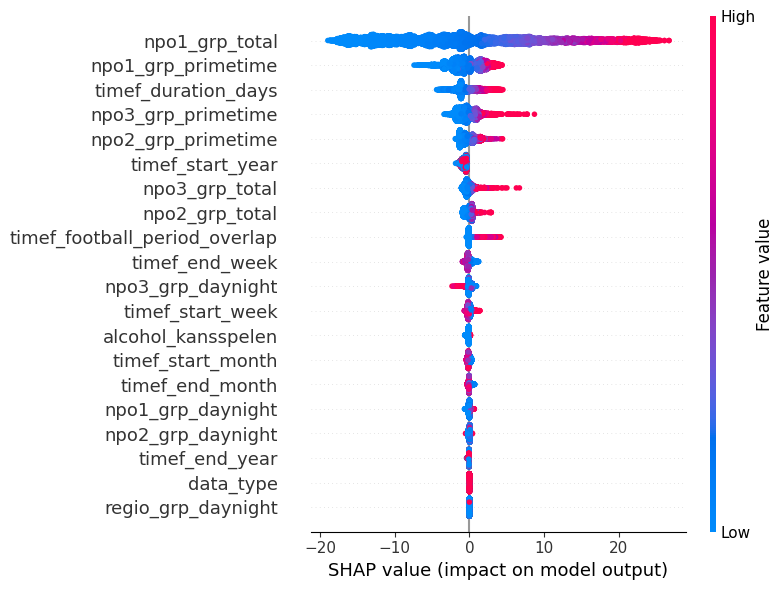

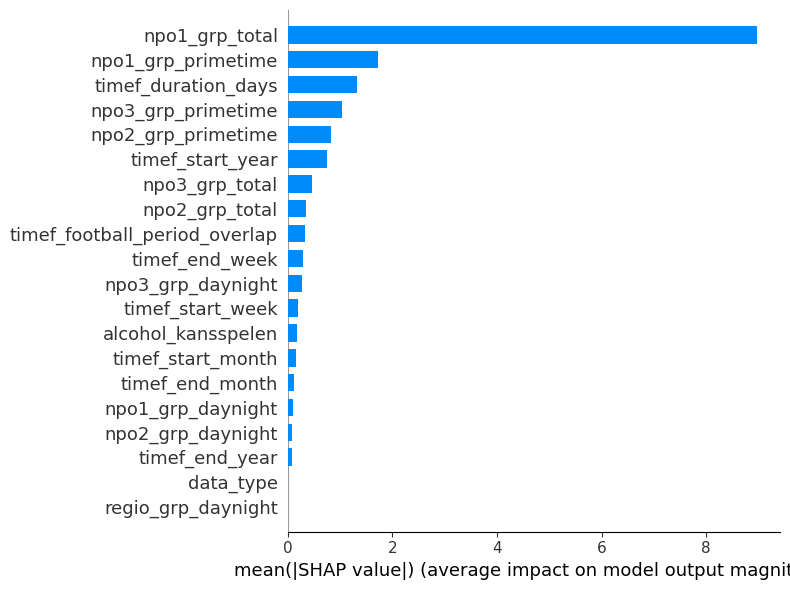

In [99]:
trainer.extract_and_visualize_shap_values()

In [ ]:
trainer.plot_dependence("data_type")

In [ ]:
trainer.df

In [ ]:

# MODEL_PARAMS = [
#     {
#         'name': 'LGBM without scaling',
#         'model': LGBMRegressor(objective='regression'),
#         'params': {
#             'model__metric': ['rmse'],
#             'model__num_leaves': [21, 31, 41, 51],
#             'model__max_depth': [8, 5, -1],
#             'model__min_data_in_leaf': [20, 50, 100],
#             'model__min_sum_hessian_in_leaf': [1e-3, 1e-2, 1e-1],
#             'model__feature_fraction': [0.8, 0.9, 1.0],
#             'model__bagging_fraction': [0.8, 0.9, 1.0],
#             'model__bagging_freq': [0, 1, 5],
#             'model__learning_rate': [0.01, 0.05, 0.1],
#             'model__lambda_l1': [0.0, 0.1, 0.5],
#             'model__lambda_l2': [0.0, 0.1, 0.5],
#             'model__max_bin': [255, 511],
#             'model__seed': [42],
#             'model__verbose': [-1]
#         },
#         'scaling': 'unscaled'
#     },
#     {
#         'name': 'Gradient Boosting Regressor without scaling',
#         'model': GradientBoostingRegressor(),
#         'params': {
#             'model__n_estimators': [200, 300, 400],
#             'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
#             'model__max_depth': [3, 5, 8],
#             'model__min_samples_split': [2, 5, 10],
#             'model__min_samples_leaf': [1, 2, 4],
#             'model__subsample': [0.8, 0.9, 1.0],
#             'model__max_features': ['auto', 'sqrt', 'log2'],
#             'model__random_state': [42]
#         },
#         'scaling': 'unscaled'
#     },
#     {
#         'name': 'SVR with scaling',
#         'model': SVR(),
#         'params': {
#             'model__C': [0.1, 1, 10, 100],
#             'model__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
#             'model__degree': [3, 4, 5],
#             'model__gamma': ['scale', 'auto'],
#             'model__coef0': [0.0, 0.1, 0.5],
#             'model__tol': [1e-3, 1e-4, 1e-5],
#             'model__epsilon': [0.1, 0.2, 0.5],
#             'model__shrinking': [True, False],
#             'model__cache_size': [200],
#             'model__max_iter': [-1, 1000, 2000]
#         },
#         'scaling': 'scaled'
#     },
#     {
#         'name': 'Hist Gradient Boosting Regressor without scaling',
#         'model': HistGradientBoostingRegressor(),
#         'params': {
#             'model__max_iter': [75, 100, 125],
#             'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
#             'model__max_depth': [None, 5, 8, 10],
#             'model__min_samples_leaf': [20, 50, 100],
#             'model__max_leaf_nodes': [31, 61, None],
#             'model__l2_regularization': [0.0, 0.1, 0.5],
#             'model__early_stopping': [True, False],
#             'model__scoring': ['loss', 'r2'],
#             'model__validation_fraction': [0.1, 0.2],
#             'model__n_iter_no_change': [10, 20],
#             'model__random_state': [42]
#         },
#         'scaling': 'unscaled'
#     },
#     {
#         'name': 'Principal Component Regression (PCR) with scaling',
#         'model': Pipeline([
#             ('pca', PCA()),
#             ('model', LinearRegression())
#         ]),
#         'params': {
#             'pca__n_components': [5, 10, 15, 20],
#             'model__fit_intercept': [True, False],
#             'model__normalize': [True, False]
#         },
#         'scaling': 'scaled'
#     },
#     {
#         'name': 'Partial Least Squares (PLS) with scaling',
#         'model': PLSRegression(),
#         'params': {
#             'n_components': [2, 5, 10, 15],
#             'scale': [True, False],
#             'max_iter': [500, 1000, 2000],
#             'tol': [1e-06, 1e-05, 1e-04]
#         },
#         'scaling': 'scaled'
#     }
# ]

###
# query = trainer.construct_query()
# df = trainer.fetch_and_prep_data(query)

# train_data, test_data = trainer.split_data(df, TEST_SET_DATE)
# X_train, y_train, X_test, y_test = trainer.prepare_features_and_target(train_data, test_data)


In [ ]:
'''
MODEL_PARAMS = [

    {
        'name': 'LGBM without scaling',
        'model': LGBMRegressor(objective='regression'),
        'params': {
            'model__metric': ['rmse'],
            'model__num_leaves': [41],
            'model__max_depth': [4],
            # 'model__min_data_in_leaf': [20, 50, 80],
            # 'model__min_sum_hessian_in_leaf': [1e-3, 1e-2, 1e-1],
            # 'model__feature_fraction': [0.8, 1.0],
            # 'model__bagging_fraction': [0.8, 1.0],
            # 'model__learning_rate': [0.01, 0.05],
            'model__lambda_l1': [0.1, 0.5],
            'model__lambda_l2': [0.1, 0.5],
            'model__max_bin': [255, 511],
            'model__verbose': [1],
            'model__seed': [42]
        },
        'scaling': 'unscaled'
    },
    # {
    #     'name': 'Gradient Boosting Regressor without scaling',
    #     'model': GradientBoostingRegressor(),
    #     'params': {
    #         'model__learning_rate': [0.03],
    #         'model__max_depth': [5],
    #         'model__max_features': ['sqrt'],
    #         'model__min_samples_leaf': [1],
    #         'model__min_samples_split': [10],
    #         'model__n_estimators': [200],
    #         'model__verbose': [1],
    #         'model__random_state': [42],
    #         'model__subsample': [0.8]
    #     },
    #     'scaling': 'unscaled'
    # },
    # {
    #     'name': 'Hist Gradient Boosting Regressor without scaling',
    #     'model': HistGradientBoostingRegressor(),
    #     'params': {
    #         'model__max_iter': [75, 100, 125],
    #         'model__learning_rate': [0.01, 0.1],
    #         'model__max_depth': [5, 8, 10],
    #         'model__verbose': [1],
    #         'model__random_state': [42]
    #     },
    #     'scaling': 'unscaled'
    # }
]
'''